In [73]:
import pandas as pd
import matplotlib.pyplot  as plt
from metrics import metrics
from model import generics
from scipy.stats import wilcoxon
pd.set_option('display.max_rows', 2000)
pd.set_option('display.max_columns', 2000)
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [74]:
experiment_id = 'hourwindspeed'

In [75]:
df_mean_metrics, df_all_metrics, df_prevs = metrics.open_fold_result(experiment_id, normalize=False)

/home/domingosjr/experiments/src/metrics/metrics.py:347: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_metric = pd.DataFrame(all_metrics).fillna(-1).infer_objects(copy=False)
/home/domingosjr/experiments/src/metrics/metrics.py:347: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_metric = pd.DataFrame(all_metrics).fillna(-1).infer_objects(copy=False)
/home/domingosjr/experiments/src/metrics/metrics.py:347: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_obje

In [98]:
df_all_metrics[['horizonte', 'name']] = df_all_metrics['model'].str.extract(r'(\d+)(.+)')
df_mean_metrics[['horizonte', 'name']] = df_mean_metrics['model'].str.extract(r'(\d+)(.+)')


In [101]:
df_mean_metrics.index.str.extract(r"(\d+)(.+)")

AttributeError: Can only use .str accessor with Index, not MultiIndex

In [99]:
df_mean_metrics.head()

MSE      RMSE       MAPE  \
ts                         model                                              
windspeedcampinagrandehour 24arima            0.643935  0.802456  15.689360   
                           24combmean         0.594258  0.770877  14.744894   
                           24elm              0.624750  0.790363  15.338520   
                           24elmbagg100.50.5  0.613290  0.783046  15.362242   
                           24elmbagg100.50.8  0.605363  0.778040  15.207109   

                                                  SMAPE       MAE      theil  \
ts                         model                                               
windspeedcampinagrandehour 24arima            15.233836  0.606614   2.808974   
                           24combmean         14.652017  0.585192  16.891222   
                           24elm              15.100101  0.604254  10.029042   
                           24elmbagg100.50.5  14.899776  0.597968  19.622413   
                           24elmbagg100.50.8  14.840215  0.595056  19.994376   

                                                   ARV        IA      POCID  \
ts                         model                                              
windspeedcampinagrandehour 24arima            0.855038  0.769414  66.666667   
                           24combmean         1.545529  0.709498  65.171233   
                           24elm              1.601067  0.694974  60.821918   
                           24elmbagg100.50.5  1.586790  0.699867  63.070776   
                           24elmbagg100.50.8  1.656199  0.697679  63.025114   

                                              val_metric  time_testing  \
ts                         model                                         
windspeedcampinagrandehour 24arima                   inf     -1.000000   
                           24combmean                inf     -1.000000   
                           24elm                0.821170      0.000529   
                           24elmbagg100.50.5    0.818611      0.017444   
                           24elmbagg100.50.8    0.813060      0.023641   

                                              time_training horizonte name  
ts                         model                                            
windspeedcampinagrandehour 24arima                -1.000000       NaN  NaN  
                           24combmean             -1.000000       NaN  NaN  
                           24elm                   0.092600       NaN  NaN  
                           24elmbagg100.50.5       0.155017       NaN  NaN  
                           24elmbagg100.50.8       0.128526       NaN  NaN

In [93]:
df_group.head()

,ts,model,MSE,RMSE,MAPE,SMAPE,MAE,theil,ARV,IA,POCID,val_metric,time_testing,time_training
0,windspeedcampinagrandehour,24arima,0.643935,0.802456,15.689360,15.233836,0.606614,2.808974,0.855038,0.769414,66.666667,inf,-1.000000,-1.000000
1,windspeedcampinagrandehour,24combmean,0.594258,0.770877,14.744894,14.652017,0.585192,16.891222,1.545529,0.709498,65.171233,inf,-1.000000,-1.000000
2,windspeedcampinagrandehour,24elm,0.624750,0.790363,15.338520,15.100101,0.604254,10.029042,1.601067,0.694974,60.821918,0.821170,0.000529,0.092600
3,windspeedcampinagrandehour,24elmbagg100.50.5,0.613290,0.783046,15.362242,14.899776,0.597968,19.622413,1.586790,0.699867,63.070776,0.818611,0.017444,0.155017
4,windspeedcampinagrandehour,24elmbagg100.50.8,0.605363,0.778040,15.207109,14.840215,0.595056,19.994376,1.656199,0.697679,63.025114,0.813060,0.023641,0.128526


In [95]:
# selection based on validation considering sufix
df_selected = pd.DataFrame()

sufix_modelos_to_agroup = [
    '24elmbagg', '48elmbagg', '72elmbagg',
    '24mlpbagg', '48mlpbagg', '72mlpbagg',
    '24rf', '48rf', '72rf', 
]

df_group = df_mean_metrics.reset_index().copy()

for sufix_atual in sufix_modelos_to_agroup:
    print('*' * 100)
    print(sufix_atual)
    filter_cond = df_group['model'].apply(
        lambda x: sufix_atual in x if pd.notna(x) else False
    )
    df_fitered = df_group[filter_cond].copy()
    
    display(df_fitered['ts'].value_counts())
    idx_min = df_fitered.groupby("ts")["val_metric"].idxmin()
    resultado = df_fitered.loc[idx_min, ["ts", "model", "MSE", 'MAPE', 'MAE', 'horizonte', 'name']]
    resultado['sufix'] = sufix_atual
    df_selected = pd.concat([df_selected, resultado])

****************************************************************************************************
24elmbagg


ts
windspeedcampinagrandehour     12
windspeedmaceiohour            12
windspeedsalvadorhour          12
windspeedcaruaruhour            1
windspeedcastelodopiauihour     1
Name: count, dtype: int64

****************************************************************************************************
48elmbagg


ts
windspeedcampinagrandehour     12
windspeedmaceiohour            12
windspeedsalvadorhour          12
windspeedcaruaruhour            1
windspeedcastelodopiauihour     1
Name: count, dtype: int64

****************************************************************************************************
72elmbagg


...

ts
windspeedcampinagrandehour    12
windspeedmaceiohour           12
windspeedsalvadorhour         12
Name: count, dtype: int64

****************************************************************************************************
48rf


ts
windspeedcampinagrandehour    12
windspeedmaceiohour           12
windspeedsalvadorhour         12
Name: count, dtype: int64

****************************************************************************************************
72rf


ts
windspeedcampinagrandehour    12
windspeedmaceiohour           12
windspeedsalvadorhour         12
Name: count, dtype: int64

In [21]:
len([c for c in df_mean_metrics.reset_index()['model'].unique().tolist() if 'svrbagg1' in c])

0

In [22]:
df_mean_metrics.reset_index()['model'].unique()

array(['24arima', '24combmean', '24elm', '24elmbagg100.50.5',
       '24elmbagg100.50.8', '24elmbagg100.51', '24elmbagg100.80.5',
       '24elmbagg100.80.8', '24elmbagg100.81', '24elmbagg1000.80.8',
       '24elmbagg1010.5', '24elmbagg1010.8', '24elmbagg300.50.5',
       '24elmbagg300.50.8', '24elmbagg300.80.5', '24elmbagg300.80.8',
       '24elmbagg500.50.5', '24elmbagg500.50.8', '24elmbagg500.80.5',
       '24elmbagg500.80.8', '24kan', '24ma', '24mlp', '24mlpbagg100.50.5',
       '24mlpbagg100.50.8', '24mlpbagg100.80.5', '24mlpbagg100.80.8',
       '24mlpbagg300.50.5', '24mlpbagg300.50.8', '24mlpbagg300.80.5',
       '24mlpbagg300.80.8', '24mlpbagg500.50.5', '24mlpbagg500.50.8',
       '24mlpbagg500.80.5', '24mlpbagg500.80.8', '24nhits', '24rf',
       '24rf.100', '24rf.50', '24rf100.50.5', '24rf100.50.8',
       '24rf100.80.5', '24rf100.80.8', '24rf300.50.5', '24rf300.50.8',
       '24rf300.80.5', '24rf300.80.8', '24rf500.50.5', '24rf500.50.8',
       '24rf500.80.5', '24rf500.80.8',

In [11]:
df_mean_metrics.columns

Index(['MSE', 'RMSE', 'MAPE', 'SMAPE', 'MAE', 'theil', 'ARV', 'IA', 'POCID',
       'val_metric', 'time_testing', 'time_training'],
      dtype='object')

In [32]:
models = ['24elm', 
        '24elmbagg100.50.5',
        '24elmbagg100.80.5',
        '24elmbagg100.50.8', 
        '24elmbagg100.80.8', 
        '24elmbagg300.50.5',
        '24elmbagg300.50.8', 
        '24elmbagg300.80.5', 
        '24elmbagg300.80.8',
        '24elmbagg500.50.5', 
        '24elmbagg500.50.8', 
        '24elmbagg500.80.5',
        '24elmbagg500.80.8',
         
]


to_show = df_mean_metrics.reset_index()
to_show = to_show[to_show['model'].isin(models)]
to_show['model'] = pd.Categorical(
    to_show['model'], 
    categories=models, 
    ordered=True
)

In [33]:
to_show.reset_index().sort_values(['ts', 'model'])[['ts', 'model', "MSE", 'MAPE', 'MAE',  'val_metric']]

,ts,model,MSE,MAPE,MAE,val_metric
0,windspeedcampinagrandehour,24elm,0.624750,15.338520,0.604254,0.821170
1,windspeedcampinagrandehour,24elmbagg100.50.5,0.613290,15.362242,0.597968,0.818611
3,windspeedcampinagrandehour,24elmbagg100.80.5,0.615081,15.415125,0.599185,0.819196
2,windspeedcampinagrandehour,24elmbagg100.50.8,0.605363,15.207109,0.595056,0.813060
4,windspeedcampinagrandehour,24elmbagg100.80.8,0.602573,15.210434,0.593369,0.812227
5,windspeedcampinagrandehour,24elmbagg300.50.5,0.611215,15.334373,0.597457,0.816937
6,windspeedcampinagrandehour,24elmbagg300.50.8,0.602641,15.185379,0.593576,0.812235
7,windspeedcampinagrandehour,24elmbagg300.80.5,0.609338,15.333767,0.596117,0.815354
8,windspeedcampinagrandehour,24elmbagg300.80.8,0.601884,15.165523,0.593424,0.811669
9,windspeedcampinagrandehour,24elmbagg500.50.5,0.606278,15.275161,0.594927,0.815292


In [10]:
metric = 'RMSE'

proposed_list = []
for k, df in df_mean_metrics.reset_index().groupby('ts'):
    #arima = df[df['model'] == 'arima'][metric].iloc[0]
    #svr = df[df['model'] == 'arima'][metric].iloc[0]
    #mlp = df[df['model'] == 'arima'][metric].iloc[0]

    #df_arima[k] = (df.set_index('model')[metric] < arima)
    #df_svr[k] = (df.set_index('model')[metric] < svr)
    #df_mlp[k] = (df.set_index('model')[metric] < mlp)

    svr_proposed = df[( (df['model'].str.contains("1ammeanenscdsrc12k10")))].copy()
    if svr_proposed.shape[0]>0:
        proposed_list.append(pd.DataFrame(svr_proposed.iloc[svr_proposed['val_metric'].argmin()]).T)

    mlp_proposed = df[( (df['model'].str.contains("mlpkpssfalsep")) )].copy()
    if mlp_proposed.shape[0]>0:
        proposed_list.append(pd.DataFrame(mlp_proposed.iloc[mlp_proposed['val_metric'].argmin()]).T)
    order_personalizada =  [ 
               #'1mlp', 
              
              #'1ammean100', 
              #'1as', 
              #'1asens', 
              ##'1am' ,
               '1aquant',
               '1aquantmean100', 
              
              #'1ammean100cdsrc0.1k20', '1ammean100cdsrc0.1k40', '1ammean100cdsrc0.1k80' , 
              #'1ammean100cmostrecentrc1k20', '1ammean100cmostrecentrc1k40', '1ammean100cmostrecentrc1k80', 
               '1aquantmean100cdsrc0.1k20', '1aquantmean100cdsrc0.1k40', '1aquantmean100cdsrc0.1k80',
               '1aquantmean100cmostrecentrc1k20', '1aquantmean100cmostrecentrc1k40', '1aquantmean100cmostrecentrc1k80', 
               #'1asenscdsrc0.1k20',  '1asenscdsrc0.1k40',  '1asenscdsrc0.1k80',
               #'1asenscmostrecentrc1k20',  '1asenscmostrecentrc1k40', '1asenscmostrecentrc1k80',
                '1arima',
                '1svr', 
            ]
    proposed_list.append(
        df[df['model'].isin(
            order_personalizada
        )]
    )

In [11]:
df_show = pd.concat(proposed_list)[['ts', 'model', 'RMSE', 'MAPE', 'MAE']]

df_show['model'] = pd.Categorical(df_show['model'], categories=order_personalizada, ordered=True)

In [12]:
df_show.sort_values(['ts', 'model'])

,ts,model,RMSE,MAPE,MAE


In [13]:
def get_hipotesis(metrics_p1, metrics_p2):
    stat, p = wilcoxon(metrics_p1, metrics_p2, alternative='two-sided')
    # interpret
    alpha = 0.05
    if p > alpha:
        #print('Same distribution (fail to reject H0)')
        to_print = '\'='
    else:
        stat, p = wilcoxon(metrics_p1, metrics_p2, alternative='less')
        if p > alpha:
             to_print = '\'-'
        else:
            to_print = '\'+'
        #print('Different distribution (reject H0)')

    return to_print

def columns_x_columns(df_pivot):
    all_comparasion = []
    for c1 in df_pivot.columns:
        result_base = {}
        result_base['base'] = c1 
        for c2 in df_pivot.columns:
            if c1!=c2:
                result = get_hipotesis(df_pivot[c1], df_pivot[c2])
                result_base[c2] = result
            else:
                result_base[c2] = '\'='
        all_comparasion.append(result_base)
    
    df_result = pd.DataFrame(all_comparasion)
    
    display(df_result[df_result['base'] == '1mpfs2050'])

all_execs = []
for key, df_serie in df_all_metrics.groupby(['ts']):
    try:
        print(key)
        df_pivot = df_serie.pivot(columns= 'model', values='RMSE' )
        df_pivot = df_pivot.ffill()
        to_plot = df_serie.pivot(columns= 'model', values='RMSE' )[[
            '1arima', '1elm', '1kan', '1mlp', '1mp2050', '1mpfs2050', '1nhits', '1svr', '1tcn', '1scn']
            ]
        
        ax = to_plot.rename(columns={
            '1arima': 'SARIMA',
            '1kanval': 'KAN',
            '1mlp': 'MLP',
            '1nhits':"NHITS",
            '1tcn': 'TCN',
            'combmean': 'HetMean',
            'hmrc20k3': 'HetDs',
           '1svrbagg500.80.8rc100k20': 'Proposed'
        }
        ).plot.box(figsize = (6,5), rot=90)
        ax.set_ylabel('SMAPE')
        ax.set_xlabel('Model')
        #plt.savefig(f'box{key[0]}.pdf', format='pdf', bbox_inches='tight')
        plt.show()
        columns_x_columns(df_pivot)
    except:
        print(f'error {key}')

('windspeedcampinagrandehour',)
error ('windspeedcampinagrandehour',)
('windspeedcaruaruhour',)
error ('windspeedcaruaruhour',)
('windspeedcastelodopiauihour',)
error ('windspeedcastelodopiauihour',)
('windspeedmaceiohour',)
error ('windspeedmaceiohour',)
('windspeedsalvadorhour',)
error ('windspeedsalvadorhour',)


In [14]:
df_all_metrics['model'].unique()

array(['24kan', '72rf', '72elm', '48kan', '48svr', '72rf.50', '24rf.100',
       '48ma', '72kan', '72mlp', '24mlpbagg500.80.8', '48elmbagg500.80.8',
       '24ma', '24elmbagg1000.80.8', '24combmean', '72nhits', '72tcn',
       '48elm', '48arima', '48rf', '48tcn', '48mlpbagg500.80.8',
       '24arima', '48elmbagg1000.80.8', '24rf.50', '72svr', '48rf.100',
       '48combmean', '24elmbagg500.80.8', '48nhits', '24nhits', '72ma',
       '72arima', '24svr', '72elmbagg500.80.8', '24tcn',
       '72elmbagg1000.80.8', '24rf', '72mlpbagg500.80.8', '48mlp',
       '48rf.50', '24mlp', '72rf.100', '24elm', '72combmean'],
      dtype=object)

In [82]:
df_all = df_all_metrics[~df_all_metrics['ts'].isin(['windspeedcaruaruhour', 'windspeedcastelodopiauihour'])].reset_index()
df_all = df_all.pivot(index=['index', 'ts', 'horizonte' ], values='RMSE', columns='name').groupby(['ts', 'horizonte']).ffill().reset_index()

In [83]:
df_all['ts'].unique()

array(['windspeedcampinagrandehour', 'windspeedmaceiohour',
       'windspeedsalvadorhour'], dtype=object)

In [84]:
df_all.head()

name,index,ts,horizonte,arima,combmean,elm,elmbagg100.50.5,elmbagg100.50.8,elmbagg100.80.5,elmbagg100.80.8,elmbagg300.50.5,elmbagg300.50.8,elmbagg300.80.5,elmbagg300.80.8,elmbagg500.50.5,elmbagg500.50.8,elmbagg500.80.5,elmbagg500.80.8,kan,ma,mlp,mlpbagg100.50.5,mlpbagg100.50.8,mlpbagg100.80.5,mlpbagg100.80.8,mlpbagg300.50.5,mlpbagg300.50.8,mlpbagg300.80.5,mlpbagg300.80.8,mlpbagg500.50.5,mlpbagg500.50.8,mlpbagg500.80.5,mlpbagg500.80.8,nhits,rf100.50.5,rf100.50.8,rf100.80.5,rf100.80.8,rf300.50.5,rf300.50.8,rf300.80.5,rf300.80.8,rf500.50.5,rf500.50.8,rf500.80.5,rf500.80.8,svr,tcn
0,0,windspeedcampinagrandehour,24,0.802456,0.765325,0.789140,0.779169,0.781068,0.770928,0.767133,0.783812,0.771230,0.788121,0.771404,0.776718,0.775161,0.780144,0.779480,0.784238,0.947169,0.833368,0.859553,0.843733,0.861074,0.828986,0.862950,0.838348,0.881035,0.842926,0.873261,0.844439,0.865842,0.845632,0.773079,0.818709,0.823975,0.830725,0.813320,0.813127,0.814617,0.818352,0.809336,0.816789,0.811973,0.817020,0.810553,0.800308,0.867779
1,0,windspeedcampinagrandehour,48,0.925404,0.855230,0.889082,0.861339,0.866427,0.861399,0.865421,0.867778,0.856496,0.865443,0.859375,0.864284,0.863426,0.866270,0.859931,0.876167,0.998760,0.934697,0.960348,0.930182,0.963604,0.952016,0.951668,0.932038,0.962016,0.937442,0.963906,0.936035,0.959610,0.934589,0.868405,0.898400,0.875033,0.904579,0.894102,0.893867,0.884977,0.895929,0.886603,0.894585,0.901227,0.893872,0.883006,0.902139,0.913852
2,0,windspeedcampinagrandehour,72,0.982239,0.897348,0.912326,0.912643,0.900492,0.901187,0.907222,0.903797,0.903508,0.908855,0.902702,0.906487,0.900715,0.905105,0.898387,0.917222,1.031012,0.978508,1.000239,0.985591,0.984728,0.971250,0.991230,0.979486,1.000919,0.977936,0.999749,0.978264,0.996560,0.976088,0.916526,0.939360,0.914097,0.970469,0.933419,0.929177,0.940138,0.939981,0.934519,0.934736,0.936125,0.940284,0.939138,0.990414,0.950502
3,0,windspeedmaceiohour,24,1.710248,0.899015,0.891494,0.948992,0.924114,0.927170,0.917356,0.917036,0.915125,0.923009,0.915760,0.909770,0.915352,0.916856,0.919007,0.915883,1.787225,1.012028,1.056568,0.991883,1.015919,0.996976,1.015107,0.994302,1.018193,1.011465,1.020670,0.996936,1.018044,0.995469,0.904517,1.014565,0.977484,0.999719,0.998659,0.955473,0.970314,0.971076,0.986025,0.959890,0.966864,0.956328,0.961215,0.969246,0.991044
4,0,windspeedmaceiohour,48,1.086662,1.018380,1.011909,1.012071,1.028136,1.012870,1.018737,1.034040,1.023399,1.027011,1.020956,1.026756,1.020281,1.021522,1.019123,1.025057,1.845705,1.145600,1.197228,1.144087,1.142146,1.161474,1.177362,1.137954,1.174050,1.140073,1.164840,1.145288,1.167967,1.145099,1.024262,1.160068,1.149900,1.125636,1.115422,1.104794,1.116754,1.098917,1.102149,1.098513,1.105420,1.095277,1.116927,1.084068,1.075600


In [30]:
df_all.columns

Index(['index', 'ts', 'horizonte', 'arima', 'combmean', 'elm',
       'elmbagg1000.80.8', 'elmbagg500.80.8', 'kan', 'ma', 'mlp',
       'mlpbagg500.80.8', 'nhits', 'rf', 'rf.100', 'rf.50', 'svr', 'tcn'],
      dtype='object', name='name')

In [31]:
models = ['arima', 'elm', 'kan', 'mlp', 'nhits', 'svr', 'tcn', 'rf.50', # 'combmean', 
          'elmbagg500.80.8', 'mlpbagg500.80.8'
         ]

             meanrank    median       mad  ci_lower  ci_upper effect_size  \
$ENS_{ELM}$  2.077778  0.860307  0.160904   0.61169  0.917058         0.0   
ELM          3.833333  0.875008  0.134486  0.620464  0.926809   -0.066871   
NHITS        4.655556  0.879226  0.134657  0.717831  0.916526   -0.086012   
KAN          4.900000  0.877168  0.145552   0.70881  0.918552   -0.074129   
SVR          5.344444  0.902139  0.181928  0.613833  0.990414   -0.164295   
$ENS_{DT}$   5.411111  0.891370  0.207525   0.61684  0.963072   -0.112838   
$ENS_{MLP}$  6.666667  0.935098  0.207404  0.614631  0.995469   -0.271776   
MLP          6.800000  0.928938  0.209862  0.617349  0.991934   -0.247556   
ARIMA        7.377778  0.925404  0.281437  0.618043  1.086662   -0.191539   
TCN          7.933333  0.907079  0.168606  0.741956   1.00667   -0.191429   

              magnitude effect_size_above magnitude_above  
$ENS_{ELM}$  negligible               0.0      negligible  
ELM          negligible         

<Figure size 1200x500 with 0 Axes>

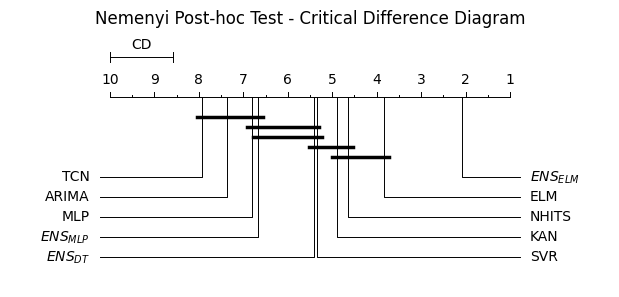


Ranks Médios:
             meanrank    median       mad  ci_lower  ci_upper effect_size  \
$ENS_{ELM}$  2.077778  0.860307  0.160904   0.61169  0.917058         0.0   
ELM          3.833333  0.875008  0.134486  0.620464  0.926809   -0.066871   
NHITS        4.655556  0.879226  0.134657  0.717831  0.916526   -0.086012   
KAN          4.900000  0.877168  0.145552   0.70881  0.918552   -0.074129   
SVR          5.344444  0.902139  0.181928  0.613833  0.990414   -0.164295   
$ENS_{DT}$   5.411111  0.891370  0.207525   0.61684  0.963072   -0.112838   
$ENS_{MLP}$  6.666667  0.935098  0.207404  0.614631  0.995469   -0.271776   
MLP          6.800000  0.928938  0.209862  0.617349  0.991934   -0.247556   
ARIMA        7.377778  0.925404  0.281437  0.618043  1.086662   -0.191539   
TCN          7.933333  0.907079  0.168606  0.741956   1.00667   -0.191429   

              magnitude effect_size_above magnitude_above  
$ENS_{ELM}$  negligible               0.0      negligible  
ELM          negl

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
from autorank import autorank, plot_stats
import numpy as np

# 1. Dados de exemplo (Substitua pelo seu DataFrame real)
# Cada coluna é um algoritmo, cada linha é um dataset/fold
data = df_all[models].copy()#[df_all['ts'].isin([
    #'austres',
   # 'milk',
    #'pollution',
    #'redwine',
    #'sunspot',
    #'temperature',
    #'ozon'
#])]#[models].copy()
data = data.rename(columns={
        'arima': 'ARIMA',
        'kan': 'KAN',
        'mlp': 'MLP',
        'nhits':"NHITS",
        'tcn': 'TCN',
        'svr': 'SVR',
        'scn': 'SCN',
        'elm': 'ELM',
       'mlpbagg500.80.8': '$ENS_{MLP}$',
        'rf.50': '$ENS_{DT}$',
        'elmbagg500.80.8': '$ENS_{ELM}$',
    }
    )
# 2. Executar o autorank
# Se os dados não forem normais, ele usará Friedman automaticamente.
# Se você quiser garantir o comportamento não-paramétrico, 
# o parâmetro correto para versões recentes é 'approach'.
result = autorank(
    data, alpha=0.05, verbose=False, 
    order='ascending', 
    approach='frequentist'
)

# 3. Gerar o gráfico de Diferença Crítica (CD Diagram)
# O autorank só gera o CD diagram se o teste de Friedman for significativo
if result.posthoc == 'nemenyi':
    plt.figure(figsize=(12, 5))
    plot_stats(result)
    plt.title("Nemenyi Post-hoc Test - Critical Difference Diagram")
    plt.savefig(f'nemenyi.pdf', format='pdf', bbox_inches='tight')
    plt.show()
else:
    print(f"O teste post-hoc detectado foi: {result.posthoc}")
    print("Para gerar o CD diagram, o autorank precisa detectar dados não-paramétricos.")
    # Forçando o plot mesmo assim (se disponível para o teste detectado)
    plot_stats(result)
   

    plt.show()

# 4. Ver os ranks médios calculados
print("\nRanks Médios:")
print(result.rankdf)

In [21]:
print(f"Valor da Diferença Crítica (CD): {result.cd}")


Valor da Diferença Crítica (CD): 1.2365966316792076


In [22]:
# 1. O P-Value do teste global (Friedman)
print(f"P-value do Teste de Friedman: {result.pvalue}")

# 2. Ver se a diferença é significante (Comparando p-value com alpha)
is_significant = result.pvalue < 0.05
print(f"Existe diferença estatística global? {is_significant}")

P-value do Teste de Friedman: 3.911365242114281e-69
Existe diferença estatística global? True


****************************************************************************************************
24elmbagg


ts
windspeedcampinagrandehour     12
windspeedmaceiohour            12
windspeedsalvadorhour          12
windspeedcaruaruhour            1
windspeedcastelodopiauihour     1
Name: count, dtype: int64

****************************************************************************************************
48elmbagg


ts
windspeedcampinagrandehour     12
windspeedmaceiohour            12
windspeedsalvadorhour          12
windspeedcaruaruhour            1
windspeedcastelodopiauihour     1
Name: count, dtype: int64

****************************************************************************************************
72elmbagg


...

ts
windspeedcampinagrandehour    12
windspeedmaceiohour           12
windspeedsalvadorhour         12
Name: count, dtype: int64

****************************************************************************************************
48rf


ts
windspeedcampinagrandehour    12
windspeedmaceiohour           12
windspeedsalvadorhour         12
Name: count, dtype: int64

****************************************************************************************************
72rf


ts
windspeedcampinagrandehour    12
windspeedmaceiohour           12
windspeedsalvadorhour         12
Name: count, dtype: int64

In [88]:
df_all.head()

name,index,ts,horizonte,arima,combmean,elm,elmbagg100.50.5,elmbagg100.50.8,elmbagg100.80.5,elmbagg100.80.8,elmbagg300.50.5,elmbagg300.50.8,elmbagg300.80.5,elmbagg300.80.8,elmbagg500.50.5,elmbagg500.50.8,elmbagg500.80.5,elmbagg500.80.8,kan,ma,mlp,mlpbagg100.50.5,mlpbagg100.50.8,mlpbagg100.80.5,mlpbagg100.80.8,mlpbagg300.50.5,mlpbagg300.50.8,mlpbagg300.80.5,mlpbagg300.80.8,mlpbagg500.50.5,mlpbagg500.50.8,mlpbagg500.80.5,mlpbagg500.80.8,nhits,rf100.50.5,rf100.50.8,rf100.80.5,rf100.80.8,rf300.50.5,rf300.50.8,rf300.80.5,rf300.80.8,rf500.50.5,rf500.50.8,rf500.80.5,rf500.80.8,svr,tcn
0,0,windspeedcampinagrandehour,24,0.802456,0.765325,0.789140,0.779169,0.781068,0.770928,0.767133,0.783812,0.771230,0.788121,0.771404,0.776718,0.775161,0.780144,0.779480,0.784238,0.947169,0.833368,0.859553,0.843733,0.861074,0.828986,0.862950,0.838348,0.881035,0.842926,0.873261,0.844439,0.865842,0.845632,0.773079,0.818709,0.823975,0.830725,0.813320,0.813127,0.814617,0.818352,0.809336,0.816789,0.811973,0.817020,0.810553,0.800308,0.867779
1,0,windspeedcampinagrandehour,48,0.925404,0.855230,0.889082,0.861339,0.866427,0.861399,0.865421,0.867778,0.856496,0.865443,0.859375,0.864284,0.863426,0.866270,0.859931,0.876167,0.998760,0.934697,0.960348,0.930182,0.963604,0.952016,0.951668,0.932038,0.962016,0.937442,0.963906,0.936035,0.959610,0.934589,0.868405,0.898400,0.875033,0.904579,0.894102,0.893867,0.884977,0.895929,0.886603,0.894585,0.901227,0.893872,0.883006,0.902139,0.913852
2,0,windspeedcampinagrandehour,72,0.982239,0.897348,0.912326,0.912643,0.900492,0.901187,0.907222,0.903797,0.903508,0.908855,0.902702,0.906487,0.900715,0.905105,0.898387,0.917222,1.031012,0.978508,1.000239,0.985591,0.984728,0.971250,0.991230,0.979486,1.000919,0.977936,0.999749,0.978264,0.996560,0.976088,0.916526,0.939360,0.914097,0.970469,0.933419,0.929177,0.940138,0.939981,0.934519,0.934736,0.936125,0.940284,0.939138,0.990414,0.950502
3,0,windspeedmaceiohour,24,1.710248,0.899015,0.891494,0.948992,0.924114,0.927170,0.917356,0.917036,0.915125,0.923009,0.915760,0.909770,0.915352,0.916856,0.919007,0.915883,1.787225,1.012028,1.056568,0.991883,1.015919,0.996976,1.015107,0.994302,1.018193,1.011465,1.020670,0.996936,1.018044,0.995469,0.904517,1.014565,0.977484,0.999719,0.998659,0.955473,0.970314,0.971076,0.986025,0.959890,0.966864,0.956328,0.961215,0.969246,0.991044
4,0,windspeedmaceiohour,48,1.086662,1.018380,1.011909,1.012071,1.028136,1.012870,1.018737,1.034040,1.023399,1.027011,1.020956,1.026756,1.020281,1.021522,1.019123,1.025057,1.845705,1.145600,1.197228,1.144087,1.142146,1.161474,1.177362,1.137954,1.174050,1.140073,1.164840,1.145288,1.167967,1.145099,1.024262,1.160068,1.149900,1.125636,1.115422,1.104794,1.116754,1.098917,1.102149,1.098513,1.105420,1.095277,1.116927,1.084068,1.075600


In [96]:
df_selected

,ts,model,MSE,MAPE,MAE,horizonte,name,sufix
10,windspeedcampinagrandehour,24elmbagg300.80.8,0.601884,15.165523,0.593424,NaN,NaN,24elmbagg
138,windspeedcaruaruhour,24elmbagg500.80.8,0.455879,24.765776,0.529326,NaN,NaN,24elmbagg
171,windspeedcastelodopiauihour,24elmbagg500.80.8,0.707422,36.662741,0.683531,NaN,NaN,24elmbagg
215,windspeedmaceiohour,24elmbagg500.80.8,0.841165,39.265546,0.720644,NaN,NaN,24elmbagg
349,windspeedsalvadorhour,24elmbagg500.80.5,0.349149,43.073058,0.428073,NaN,NaN,24elmbagg
59,windspeedcampinagrandehour,48elmbagg500.80.8,0.740458,16.594960,0.652778,NaN,NaN,48elmbagg
149,windspeedcaruaruhour,48elmbagg500.80.8,0.506447,26.554922,0.565143,NaN,NaN,48elmbagg
182,windspeedcastelodopiauihour,48elmbagg500.80.8,0.759186,38.848157,0.704399,NaN,NaN,48elmbagg
252,windspeedmaceiohour,48elmbagg100.80.8,1.051672,42.903022,0.820217,NaN,NaN,48elmbagg
395,windspeedsalvadorhour,48elmbagg500.80.8,0.373219,43.573455,0.461281,NaN,NaN,48elmbagg
